> **Language & Quick Links**: [🇰🇷 Korean (`notebooks/ko/stage3_property_graph_bigquery_spanner_ko.ipynb`)](../ko/stage3_property_graph_bigquery_spanner_ko.ipynb) · **🇺🇸 English (Current Folder: `notebooks/en/`)** ｜ [Methodology Guide](../../methodology/en/03_stage3_property_graph_en.md) ｜ [Notebook Index (README)](../README.md) ｜ [Open Live Studio Tab](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage3)
>
> **Lifecycle Navigation**: [0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb) → [Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) → [Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) → **[▶ Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb)** → [Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb) → [Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb)

---

# Stage 3. [Build Graph] Zero-ETL Physical Property Graph (BigQuery / Spanner) & Parameterized ISO GQL
## Step 3.1 6 Node × 4 Edge Metamodel Design & DDL Provisioning · Step 3.2 Instance Topology & Parameterized ISO GQL / NL2GQL

Stage 3 implements **Phase 5 (Physical Property Graph Construction)**. Without duplicating data (**Zero-ETL**), `pipeline/graph_builder.py` projects the 10 BigQuery tables into `STARTER_ONTOLOGY_GRAPH` with **6 Node Labels** and **4 Edge Labels**, verifies key uniqueness via `mcp_stage3_property_graph`, visualizes both the schema metamodel and layered instance topologies, and executes multi-hop ISO GQL queries—explicitly displaying the **bound variables table**, **executed ISO GQL statement**, and **live BigQuery results** alongside Gemini NL-to-GQL (`nl2gql`).

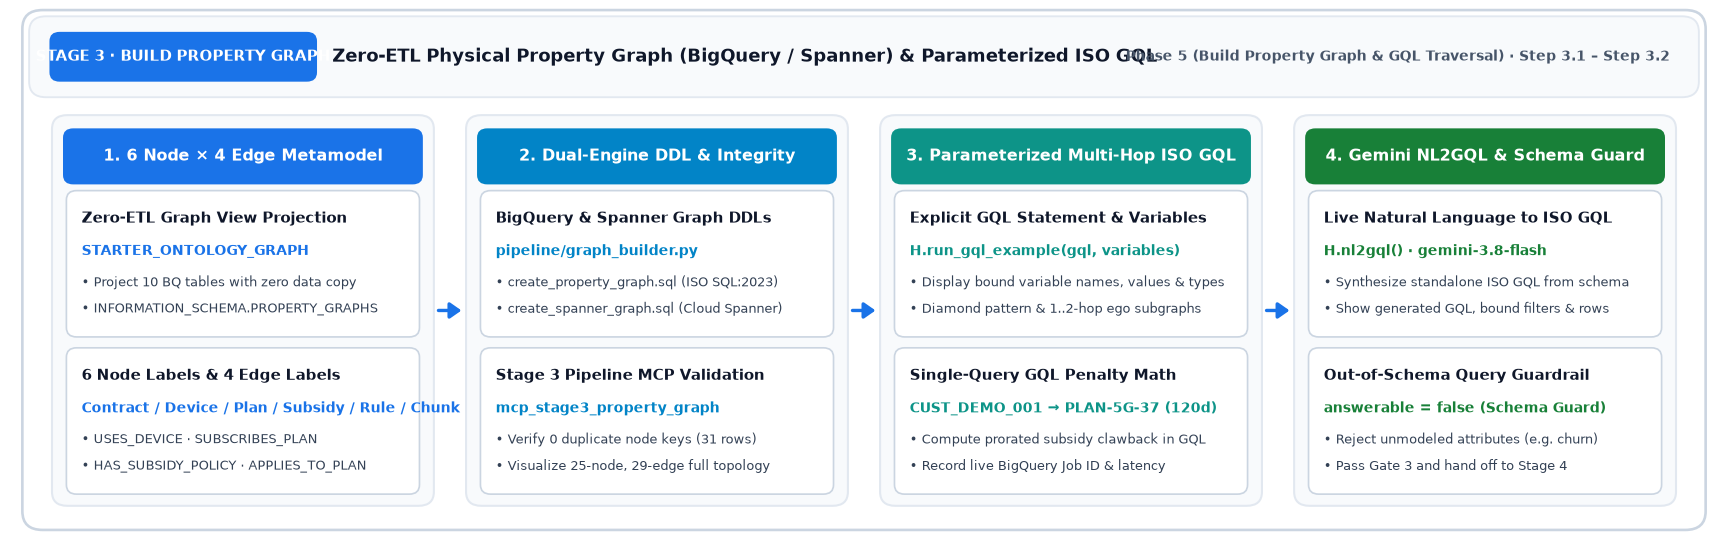


In [1]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
H.setup("en")
server = DomainMcpServer()


### 1. [Phase 5a: Graph Schema Design & Metamodel] `INFORMATION_SCHEMA.PROPERTY_GRAPHS` Metadata & 6 Node × 4 Edge Metamodel Schematic


**Live Property Graph Catalog Job**: `job_NG3UDkPTjopgFqQGmDmANTwnyJL7` (569.81 ms) · Nodes `6` · Edges `4`

,label,table,key,properties
0,CustomerContractNode,tb_customer_contract,contract_id,"[contract_id:STRING, customer_id:STRING, customer_segment:STRING, age_group:STRING, de..."
1,DeviceNode,tb_device_master,device_id,"[device_id:STRING, device_name:STRING, manufacturer:STRING, storage_gb:INT64, factory_..."
2,PlanNode,tb_plan_master,plan_id,"[plan_id:STRING, plan_name:STRING, tier_category:STRING, monthly_fee_krw:INT64, min_ma..."
3,SubsidyNode,tb_subsidy_policy,policy_id,"[policy_id:STRING, device_id:STRING, plan_id:STRING, base_subsidy_krw:INT64, additiona..."
4,DocChunkNode,tb_doc_chunks,chunk_id,"[chunk_id:STRING, source_file:STRING, section_title:STRING, content:STRING, content_sh..."
5,DomainRuleNode,tb_domain_rules,rule_id,"[rule_id:STRING, rule_name:STRING, rule_category:STRING, condition_expr:STRING, formul..."


,label,table,source,destination,properties
0,USES_DEVICE,edge_contract_device,CustomerContractNode,DeviceNode,"[contract_id:STRING, customer_id:STRING, device_id:STRING, edge_type:STRING]"
1,SUBSCRIBES_PLAN,edge_contract_plan,CustomerContractNode,PlanNode,"[contract_id:STRING, customer_id:STRING, plan_id:STRING, edge_type:STRING]"
2,HAS_SUBSIDY_POLICY,edge_subsidy_binding,DeviceNode,PlanNode,"[policy_id:STRING, device_id:STRING, plan_id:STRING, total_subsidy_krw:INT64, edge_typ..."
3,APPLIES_TO_PLAN,edge_rule_applies_to_plan,DomainRuleNode,PlanNode,"[edge_id:STRING, rule_id:STRING, plan_id:STRING, source_chunk_id:STRING, relation_labe..."


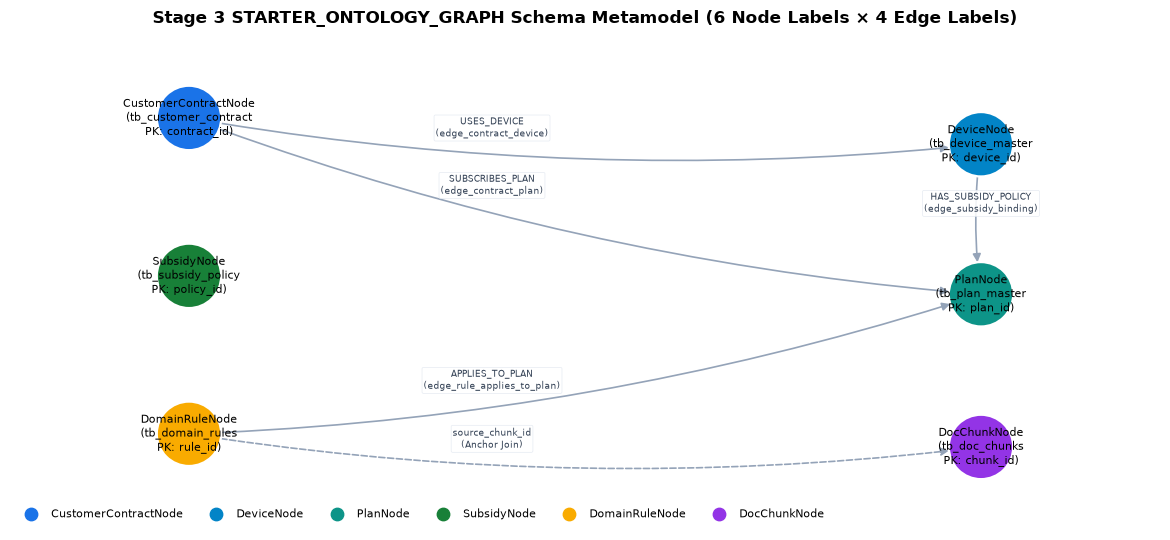

In [2]:
node_labels, edge_labels, meta = H.graph_metadata()
H.md(f"**Live Property Graph Catalog Job**: `{meta['job_id']}` ({meta['elapsed_ms']} ms) · Nodes `{len(node_labels)}` · Edges `{len(edge_labels)}`")
H.show(pd.DataFrame(node_labels))
H.show(pd.DataFrame(edge_labels))
H.draw_property_graph_metamodel()


### 2. [Phase 5b: Dual-Engine DDL Provisioning & Integrity Check] BigQuery / Spanner Graph DDL & `mcp_stage3_property_graph` Execution


In [3]:
H.show_md_file(H.ROOT / "data/output/create_property_graph.sql", max_lines=38)
H.show_md_file(H.ROOT / "data/output/create_spanner_graph.sql", max_lines=38)
res_s3 = server.execute_tool("mcp_stage3_property_graph", {"steps": ["promote_dw_nodes", "synthesize_graph_ddl", "verify_gql_templates"]})
H.show_tool(res_s3, "node_tables")
H.show(pd.DataFrame([res_s3["gql_paths"]]))


**`create_property_graph.sql`** (55 lines)

-- [Engine 1: BigQuery Property Graph] ISO SQL:2023 Property Graph DDL
-- Target Dataset: seanjung-poc.starter_ontology_dw (Provisioned via HashiCorp Terraform 1.8.5)
CREATE OR REPLACE PROPERTY GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  NODE TABLES (
    `seanjung-poc.starter_ontology_dw.tb_customer_contract`
      KEY (contract_id)
      LABEL CustomerContractNode
      PROPERTIES (contract_id, customer_id, customer_segment, age_group, device_id, plan_id, contract_type, commitment_months, elapsed_days, granted_subsidy_krw, welfare_status, status, provenance, source_ref),
    `seanjung-poc.starter_ontology_dw.tb_device_master`
      KEY (device_id)
      LABEL DeviceNode
      PROPERTIES (device_id, device_name, manufacturer, storage_gb, factory_price_krw, release_date, provenance, source_ref),
    `seanjung-poc.starter_ontology_dw.tb_plan_master`
      KEY (plan_id)
      LABEL PlanNode
      PROPERTIES (plan_id, plan_name, tier_category, monthly_fee_krw, min_maintenance_days, selective_discount_rate, provenance, source_ref),
    `seanjung-poc.starter_ontology_dw.tb_subsidy_policy`
      KEY (policy_id)
      LABEL SubsidyNode
      PROPERTIES (policy_id, device_id, plan_id, base_subsidy_krw, additional_subsidy_cap_krw, mandatory_retention_days, effective_from, provenance, source_ref),
    `seanjung-poc.starter_ontology_dw.tb_doc_chunks`
      KEY (chunk_id)
      LABEL DocChunkNode
      PROPERTIES (chunk_id, source_file, section_title, content, content_sha256, trust_tier),
    `seanjung-poc.starter_ontology_dw.tb_domain_rules`
      KEY (rule_id)
      LABEL DomainRuleNode
      PROPERTIES (rule_id, rule_name, rule_category, condition_expr, formula_expr, source_chunk_id, description_ko, provenance, source_ref)
  )
  EDGE TABLES (
    `seanjung-poc.starter_ontology_dw.edge_contract_device`
      KEY (contract_id, device_id)
      SOURCE KEY (contract_id) REFERENCES `seanjung-poc.starter_ontology_dw.tb_customer_contract` (contract_id)
      DESTINATION KEY (device_id) REFERENCES `seanjung-poc.starter_ontology_dw.tb_device_master` (device_id)
      LABEL USES_DEVICE
      PROPERTIES (contract_id, customer_id, device_id, edge_type),
    `seanjung-poc.starter_ontology_dw.edge_contract_plan`
      KEY (contract_id, plan_id)

**`create_spanner_graph.sql`** (167 lines)

-- [Engine 2: Cloud Spanner Graph] ISO GQL Property Graph Schema & DDL
-- Target Instance/DB: projects/seanjung-poc/instances/starter-spanner/databases/starter_ontology_db
-- Architecture: Low-Latency Online Graph Traversal on Cloud Spanner (Enterprise 100 PU) + BigQuery Graph Fabric (EXTERNAL_QUERY)

CREATE TABLE tb_device_master (
  device_id STRING(64) NOT NULL,
  device_name STRING(256) NOT NULL,
  manufacturer STRING(128) NOT NULL,
  storage_gb INT64 NOT NULL,
  factory_price_krw INT64 NOT NULL,
  release_date STRING(32),
  provenance STRING(64),
  source_ref STRING(256)
) PRIMARY KEY (device_id);

CREATE TABLE tb_plan_master (
  plan_id STRING(64) NOT NULL,
  plan_name STRING(256) NOT NULL,
  tier_category STRING(64) NOT NULL,
  monthly_fee_krw INT64 NOT NULL,
  min_maintenance_days INT64 NOT NULL,
  selective_discount_rate FLOAT64 NOT NULL,
  provenance STRING(64),
  source_ref STRING(256)
) PRIMARY KEY (plan_id);

CREATE TABLE tb_subsidy_policy (
  policy_id STRING(64) NOT NULL,
  device_id STRING(64) NOT NULL,
  plan_id STRING(64) NOT NULL,
  base_subsidy_krw INT64 NOT NULL,
  additional_subsidy_cap_krw INT64 NOT NULL,
  mandatory_retention_days INT64 NOT NULL,
  effective_from STRING(32),
  provenance STRING(64),
  source_ref STRING(256)
) PRIMARY KEY (policy_id);


**`mcp_stage3_property_graph`** · engine `bigquery` · status `SUCCESS` · steps `promote_dw_nodes, synthesize_graph_ddl, verify_gql_templates` · jobs 2 (905.3 ms)

[BIGQUERY] 0 duplicate keys across node tables · 10 GQL paths (Device→Plan←Rule)

- `job_38csNe0h0yLmJe4k1TMuZOCFRUBY`
- `job_qSyJcAASbYkf3szSBPoMvxqez4iL`

,node_table,row_count,duplicate_keys
0,tb_device_master,4,0
1,tb_plan_master,6,0
2,tb_subsidy_policy,5,0
3,tb_customer_contract,6,0
4,tb_doc_chunks,5,0
5,tb_domain_rules,4,0


,device_plan_rule_paths,subsidy_edges
0,10,5


### 3. [Phase 5c: Instance Data & Topology Visualization] Node & Edge Label Distribution (`%%bqsql`) and Full Instance Topology


In [4]:
%%bqsql df_gnodes
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (n)
RETURN LABELS(n)[OFFSET(0)] AS label, COUNT(*) AS nodes
GROUP BY label
ORDER BY nodes DESC


,label,nodes
0,CustomerContractNode,6
1,PlanNode,6
2,DocChunkNode,5
3,SubsidyNode,5
4,DeviceNode,4
5,DomainRuleNode,4


In [5]:
%%bqsql df_gedges
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH ()-[e]->()
RETURN LABELS(e)[OFFSET(0)] AS label, COUNT(*) AS edges
GROUP BY label
ORDER BY edges DESC


,label,edges
0,APPLIES_TO_PLAN,12
1,SUBSCRIBES_PLAN,6
2,USES_DEVICE,6
3,HAS_SUBSIDY_POLICY,5


In [6]:
%%bqsql df_all_paths
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (a)-[e]->(b)
RETURN TO_JSON(p) AS path


,path
0,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
1,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
2,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
3,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
4,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
5,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
6,"""[{\""identifier\"":\""riQAAAANAAAApgUAAAAAAAAArB..."
7,"""[{\""identifier\"":\""riQAAAANAAAApgUAAAAAAAAArB..."
8,"""[{\""identifier\"":\""riQAAAANAAAApgUAAAAAAAAArB..."
9,"""[{\""identifier\"":\""riQAAAANAAAApgUAAAAAAAAArB..."


**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | Target BigQuery Property Graph |
| `pattern (n) / (a)-[e]->(b)` | `ALL_LABELS (6N × 4E)` | Full node/edge label scan & JSON path projection |

**Executed ISO GQL Statements**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (a)-[e]->(b)
RETURN TO_JSON(p) AS path
```

,label,nodes
0,CustomerContractNode,6
1,PlanNode,6
2,DocChunkNode,5
3,SubsidyNode,5
4,DeviceNode,4
5,DomainRuleNode,4


,label,edges
0,APPLIES_TO_PLAN,12
1,SUBSCRIBES_PLAN,6
2,USES_DEVICE,6
3,HAS_SUBSIDY_POLICY,5


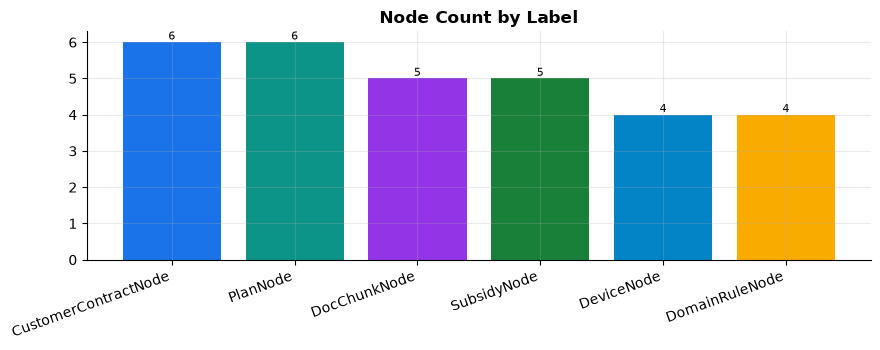

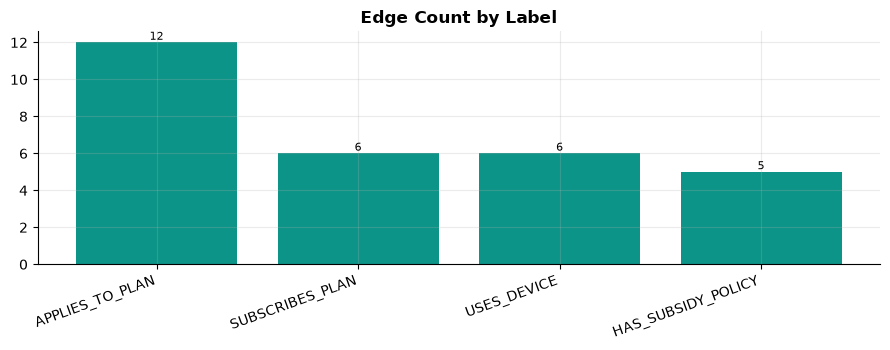

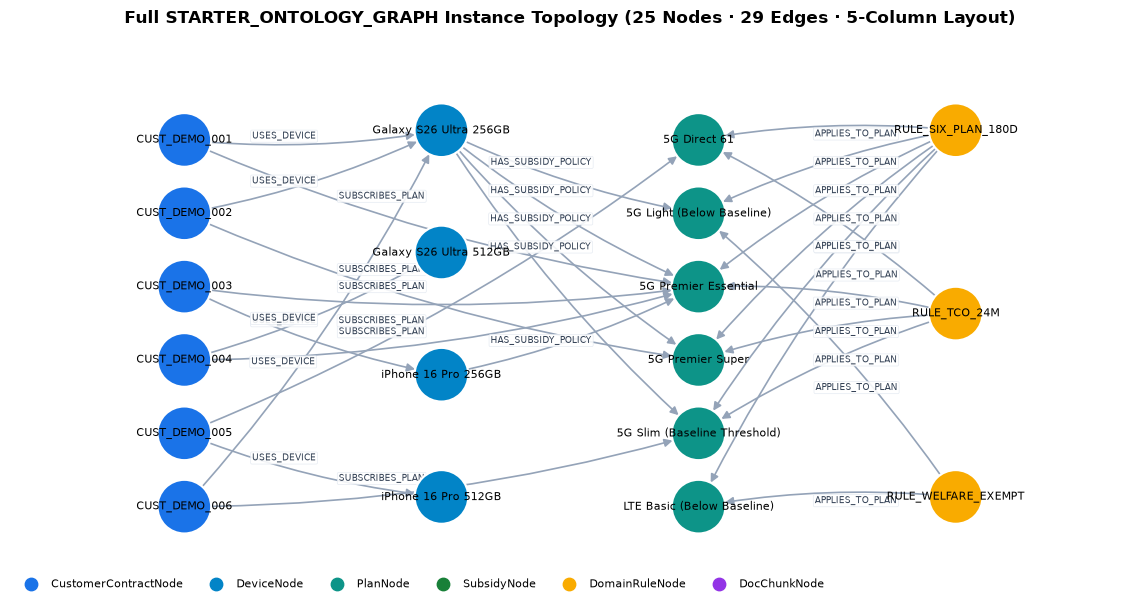

In [7]:
H.md(H._format_vars_md({
    "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "Target BigQuery Property Graph"),
    "pattern (n) / (a)-[e]->(b)": ("ALL_LABELS (6N × 4E)", "Full node/edge label scan & JSON path projection"),
}) + "**" + "Executed ISO GQL Statements" + "**\n```sql\n"
f"GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`\nMATCH p = (a)-[e]->(b)\nRETURN TO_JSON(p) AS path\n```")
H.show(df_gnodes)
H.show(df_gedges)
H.bar(df_gnodes, "label", "nodes", "Node Count by Label",
      color=[H.LABEL_COLORS.get(x, "#1A73E8") for x in H.pdf(df_gnodes)["label"]])
H.bar(df_gedges, "label", "edges", "Edge Count by Label", color="#0d9488")
nodes, edges = H.paths_to_graph(H.pdf(df_all_paths)["path"])
H.draw_graph(nodes, edges, "Full STARTER_ONTOLOGY_GRAPH Instance Topology (25 Nodes · 29 Edges · 5-Column Layout)", legend=H.LABEL_COLORS)


### 4. [Phase 5d: Parameterized Multi-Hop ISO GQL Patterns (`H.run_gql`)] Executed GQL Statements, Bound Variables, Result Tables & 1..2-Hop Ego Subgraph


In [8]:
# GQL-01: 2-Hop Customer Contract -> Device & Subscribed Plan
gql_1 = """GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode),
      (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)
RETURN c.customer_id AS customer_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days,
       d.device_name AS device_name, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw
ORDER BY customer_id"""
df_g1, _ = H.run_gql(
    gql_1,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "Property Graph view"),
        "edge_1": ("USES_DEVICE", "CustomerContractNode -> DeviceNode"),
        "edge_2": ("SUBSCRIBES_PLAN", "CustomerContractNode -> PlanNode"),
    },
    title="GQL-01 · 2-Hop Customer Contract to Device & Subscribed Plan",
)

# GQL-02: Diamond Pattern (Contract -> Device -> Subsidy -> Plan <- Contract)
gql_3 = """GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[:SUBSCRIBES_PLAN]-(c)
RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name,
       hs.total_subsidy_krw AS policy_total_subsidy_krw, c.granted_subsidy_krw AS granted_subsidy_krw
ORDER BY customer_id"""
df_g3, _ = H.run_gql(
    gql_3,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "Property Graph view"),
        "pattern": ("(c)-[:USES_DEVICE]->(d)-[hs:HAS_SUBSIDY_POLICY]->(p)<-[:SUBSCRIBES_PLAN]-(c)",
                    "4-node closed diamond consistency pattern"),
    },
    title="GQL-02 · Diamond Pattern Match (Granted Subsidy vs. Policy Total Subsidy)",
)


#### GQL-01 · 2-Hop Customer Contract to Device & Subscribed Plan
- **BigQuery ISO GQL Execution**: status `SUCCESS` · job `job_m9Mqg0AicgHSvpa_RJfg0_qRoV01` · `583 ms` · `6 rows`

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | Property Graph view |
| `edge_1` | `USES_DEVICE` | CustomerContractNode -> DeviceNode |
| `edge_2` | `SUBSCRIBES_PLAN` | CustomerContractNode -> PlanNode |

**2) Executed ISO GQL Statement**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode),
      (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)
RETURN c.customer_id AS customer_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days,
       d.device_name AS device_name, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw
ORDER BY customer_id
```

,customer_id,welfare_status,elapsed_days,device_name,plan_name,monthly_fee_krw
0,CUST_DEMO_001,NONE,120,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CUST_DEMO_002,NONE,224,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CUST_DEMO_003,SENIOR_EXEMPT,88,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CUST_DEMO_004,NONE,109,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CUST_DEMO_005,MILITARY_PAUSE_ELIGIBLE,57,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CUST_DEMO_006,NONE,170,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


#### GQL-02 · Diamond Pattern Match (Granted Subsidy vs. Policy Total Subsidy)
- **BigQuery ISO GQL Execution**: status `SUCCESS` · job `job_U60iXdqY6uwV_lBSu7ewczKo2Jv3` · `851 ms` · `4 rows`

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | Property Graph view |
| `pattern` | `(c)-[:USES_DEVICE]->(d)-[hs:HAS_SUBSIDY_POLICY]->(p)<-[:SUBSCRIBES_PLAN]-(c)` | 4-node closed diamond consistency pattern |

**2) Executed ISO GQL Statement**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[:SUBSCRIBES_PLAN]-(c)
RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name,
       hs.total_subsidy_krw AS policy_total_subsidy_krw, c.granted_subsidy_krw AS granted_subsidy_krw
ORDER BY customer_id
```

,customer_id,device_name,plan_name,policy_total_subsidy_krw,granted_subsidy_krw
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,517500,517500
1,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,575000,575000
2,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,460000,460000
3,CUST_DEMO_006,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),345000,345000


In [9]:
# GQL-03: Plan-to-DomainRule & SHA-256 DocChunk Anchor Join
target_plan_for_rules = "PLAN-5G-37"
gql_6 = f"""GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (r:DomainRuleNode)-[a:APPLIES_TO_PLAN]->(p:PlanNode),
      (ch:DocChunkNode)
WHERE p.plan_id = '{target_plan_for_rules}' AND ch.chunk_id = a.source_chunk_id
RETURN r.rule_id AS rule_id, a.relation_label_ko AS relation_label_ko, p.plan_name AS plan_name,
       ch.chunk_id AS chunk_id, ch.section_title AS section_title, SUBSTR(ch.content, 1, 90) AS excerpt
ORDER BY rule_id"""
df_g6, _ = H.run_gql(
    gql_6,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "Property Graph view"),
        "$target_plan_id (p.plan_id)": (f"'{target_plan_for_rules}'", "PlanNode target plan_id filter"),
        "ch.chunk_id": ("a.source_chunk_id", "APPLIES_TO_PLAN edge to DocChunkNode join key"),
    },
    title="GQL-03 · Plan-Bound Domain Rules Joined with SHA-256 Policy Chunks",
)

# GQL-04: Single-Query Prorated Subsidy Clawback Calculation
cust_id_param = "CUST_DEMO_001"
target_plan_param = "PLAN-5G-37"
elapsed_days_param = 120
gql_8 = f"""GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode)-[cur:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[:SUBSCRIBES_PLAN]-(c),
      (d)-[tgt:HAS_SUBSIDY_POLICY]->(t:PlanNode),
      (s1:SubsidyNode), (s2:SubsidyNode)
WHERE c.customer_id = '{cust_id_param}' AND t.plan_id = '{target_plan_param}'
  AND s1.policy_id = cur.policy_id AND s2.policy_id = tgt.policy_id
RETURN c.customer_id AS customer_id, p.plan_name AS current_plan, t.plan_name AS target_plan,
       s1.base_subsidy_krw AS current_base_subsidy_krw, s2.base_subsidy_krw AS target_base_subsidy_krw,
       s1.mandatory_retention_days AS retention_days, {elapsed_days_param} AS elapsed_days,
       CAST(ROUND((s1.base_subsidy_krw - s2.base_subsidy_krw) * (s1.mandatory_retention_days - {elapsed_days_param}) / s1.mandatory_retention_days) AS INT64) AS penalty_krw"""
df_g8, _ = H.run_gql(
    gql_8,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "Property Graph view"),
        "$customer_id (c.customer_id)": (f"'{cust_id_param}'", "Target customer_id on CustomerContractNode"),
        "$target_plan_id (t.plan_id)": (f"'{target_plan_param}'", "Target downgrade plan_id on PlanNode"),
        "$elapsed_days": (str(elapsed_days_param), "Elapsed days since activation (prorated formula input)"),
    },
    title="GQL-04 · Single-Query ISO GQL Prorated Downgrade Penalty Calculation",
)


#### GQL-03 · Plan-Bound Domain Rules Joined with SHA-256 Policy Chunks
- **BigQuery ISO GQL Execution**: status `SUCCESS` · job `job_eqP9LXWfK0aJKf1DlYDeH47UkM7l` · `531 ms` · `2 rows`

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | Property Graph view |
| `$target_plan_id (p.plan_id)` | `'PLAN-5G-37'` | PlanNode target plan_id filter |
| `ch.chunk_id` | `a.source_chunk_id` | APPLIES_TO_PLAN edge to DocChunkNode join key |

**2) Executed ISO GQL Statement**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (r:DomainRuleNode)-[a:APPLIES_TO_PLAN]->(p:PlanNode),
      (ch:DocChunkNode)
WHERE p.plan_id = 'PLAN-5G-37' AND ch.chunk_id = a.source_chunk_id
RETURN r.rule_id AS rule_id, a.relation_label_ko AS relation_label_ko, p.plan_name AS plan_name,
       ch.chunk_id AS chunk_id, ch.section_title AS section_title, SUBSTR(ch.content, 1, 90) AS excerpt
ORDER BY rule_id
```

,rule_id,relation_label_ko,plan_name,chunk_id,section_title,excerpt
0,RULE_SIX_PLAN_180D,Prorated penalty applies when downgrading below baseline,5G Light (Below Baseline),DOC_CHUNK_003,Penalty Math Formula,## 3. Penalty Settlement Computation Formula\nThe subsidy difference penalty is calcul...
1,RULE_WELFARE_EXEMPT,Penalty exemption applies for senior welfare transition,5G Light (Below Baseline),DOC_CHUNK_004,Statutory Penalty Exemptions,## 4. Statutory Penalty Exemption Clauses (Statutory Exemption Clauses)\n1. **Senior &...


#### GQL-04 · Single-Query ISO GQL Prorated Downgrade Penalty Calculation
- **BigQuery ISO GQL Execution**: status `SUCCESS` · job `job_mtMyTj4iisefgJb7gAozmWHhAL9W` · `537 ms` · `1 rows`

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | Property Graph view |
| `$customer_id (c.customer_id)` | `'CUST_DEMO_001'` | Target customer_id on CustomerContractNode |
| `$target_plan_id (t.plan_id)` | `'PLAN-5G-37'` | Target downgrade plan_id on PlanNode |
| `$elapsed_days` | `120` | Elapsed days since activation (prorated formula input) |

**2) Executed ISO GQL Statement**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode)-[cur:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[:SUBSCRIBES_PLAN]-(c),
      (d)-[tgt:HAS_SUBSIDY_POLICY]->(t:PlanNode),
      (s1:SubsidyNode), (s2:SubsidyNode)
WHERE c.customer_id = 'CUST_DEMO_001' AND t.plan_id = 'PLAN-5G-37'
  AND s1.policy_id = cur.policy_id AND s2.policy_id = tgt.policy_id
RETURN c.customer_id AS customer_id, p.plan_name AS current_plan, t.plan_name AS target_plan,
       s1.base_subsidy_krw AS current_base_subsidy_krw, s2.base_subsidy_krw AS target_base_subsidy_krw,
       s1.mandatory_retention_days AS retention_days, 120 AS elapsed_days,
       CAST(ROUND((s1.base_subsidy_krw - s2.base_subsidy_krw) * (s1.mandatory_retention_days - 120) / s1.mandatory_retention_days) AS INT64) AS penalty_krw
```

,customer_id,current_plan,target_plan,current_base_subsidy_krw,target_base_subsidy_krw,retention_days,elapsed_days,penalty_krw
0,CUST_DEMO_001,5G Premier Essential,5G Light (Below Baseline),450000,150000,180,120,100000


#### GQL-05 · 1..2-Hop Variable-Length Ego Subgraph Extraction for CUST_DEMO_001
- **BigQuery ISO GQL Execution**: status `SUCCESS` · job `job_48PyNUIUox__eEcROrnskIewvYIh` · `1,609 ms` · `16 rows`

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | Property Graph view |
| `$customer_id (c.customer_id)` | `'CUST_DEMO_001'` | Center ego node customer_id |
| `quantifier -{1,2}-` | `1..2 hops` | ISO GQL variable-length path quantifier |

**2) Executed ISO GQL Statement**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (c:CustomerContractNode)-[e]-{1,2}(n)
WHERE c.customer_id = 'CUST_DEMO_001'
RETURN LABELS(n)[OFFSET(0)] AS reached_label, PATH_LENGTH(p) AS hops, TO_JSON(p) AS path
ORDER BY hops, reached_label
```

,reached_label,hops
0,DeviceNode,1
1,PlanNode,1
2,CustomerContractNode,2
3,CustomerContractNode,2
4,CustomerContractNode,2
5,CustomerContractNode,2
6,CustomerContractNode,2
7,CustomerContractNode,2
8,DeviceNode,2
9,DeviceNode,2


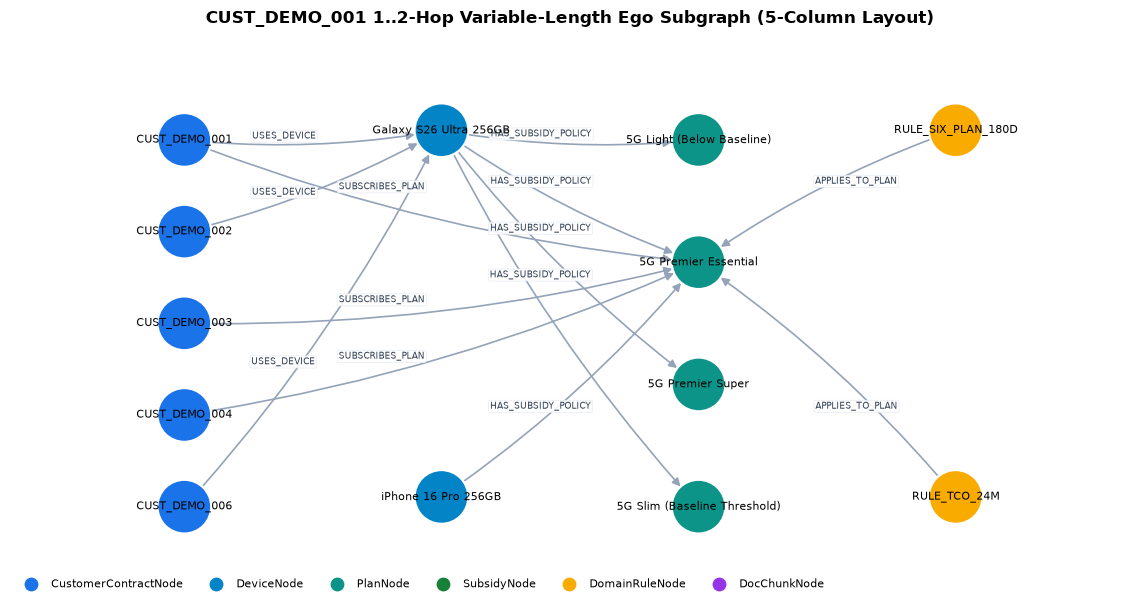

In [10]:
# GQL-05: 1..2-Hop Variable-Length Ego Subgraph for CUST_DEMO_001
ego_customer = "CUST_DEMO_001"
gql_5 = f"""GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (c:CustomerContractNode)-[e]-{{1,2}}(n)
WHERE c.customer_id = '{ego_customer}'
RETURN LABELS(n)[OFFSET(0)] AS reached_label, PATH_LENGTH(p) AS hops, TO_JSON(p) AS path
ORDER BY hops, reached_label"""
df_g5, _ = H.run_gql(
    gql_5,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "Property Graph view"),
        "$customer_id (c.customer_id)": (f"'{ego_customer}'", "Center ego node customer_id"),
        "quantifier -{1,2}-": ("1..2 hops", "ISO GQL variable-length path quantifier"),
    },
    title="GQL-05 · 1..2-Hop Variable-Length Ego Subgraph Extraction for CUST_DEMO_001",
    show_df=False,
)
H.show(df_g5[["reached_label", "hops"]])
enodes, eedges = H.paths_to_graph(H.pdf(df_g5)["path"])
H.draw_graph(enodes, eedges, "CUST_DEMO_001 1..2-Hop Variable-Length Ego Subgraph (5-Column Layout)", legend=H.LABEL_COLORS)


### 5. [Phase 5e: Live Gemini NL-to-GQL (`nl2gql`) & Schema Guard] Natural Language to ISO GQL Statement, Bound Variables & Execution


In [11]:
schema_str = H.schema_text(node_labels, edge_labels)
questions = [
    "List each customer contract with its device name, subscribed plan name, and monthly fee.",
    "For each plan, count the applied DomainRuleNodes and list their rule_ids ordered by monthly fee desc.",
    "Show base-station call quality complaints and churn scores per customer for August 2025.",
]
nl_rows = [H.nl2gql(q, schema_str) for q in questions]
H.show(pd.DataFrame(nl_rows))


**Q.** List each customer contract with its device name, subscribed plan name, and monthly fee.
- Gemini `gemini-3.8-flash`: Matches customer contracts with their associated device and subscribed plan details. (tokens 1,651, 4,934 ms)

Attempt 1 · status `SUCCESS` · job `job_rI1QqpWQlHm7lg6fppDFKYR2rAwJ` · 644 ms · 6 rows

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | Target BigQuery Property Graph |
| `graph_name` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | NL2GQL extracted filter/entity binding |

**2) Executed ISO GQL Statement**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode) RETURN c.contract_id AS contract_id, c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw ORDER BY contract_id LIMIT 50
```

,contract_id,customer_id,device_name,plan_name,monthly_fee_krw
0,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CONTRACT_DEMO_106,CUST_DEMO_006,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


**Q.** For each plan, count the applied DomainRuleNodes and list their rule_ids ordered by monthly fee desc.
- Gemini `gemini-3.8-flash`: Aggregates DomainRuleNodes connected to each PlanNode via the APPLIES_TO_PLAN edge and orders the plans by monthly fee in descending order. (tokens 1,700, 6,232 ms)

Attempt 1 · status `SUCCESS` · job `job_58Q7kyLYLfaaHCWAVcuaD7TOkys0` · 603 ms · 6 rows

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | Target BigQuery Property Graph |

**2) Executed ISO GQL Statement**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` MATCH (r:DomainRuleNode)-[:APPLIES_TO_PLAN]->(p:PlanNode) RETURN p.plan_id AS plan_id, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw, COUNT(r) AS applied_rule_count, ARRAY_AGG(r.rule_id) AS rule_ids ORDER BY monthly_fee_krw DESC LIMIT 50
```

,plan_id,plan_name,monthly_fee_krw,applied_rule_count,rule_ids
0,PLAN-5G-130,5G Premier Super,130000,2,"[{'v': 'RULE_TCO_24M'}, {'v': 'RULE_SIX_PLAN_180D'}]"
1,PLAN-5G-85,5G Premier Essential,85000,2,"[{'v': 'RULE_TCO_24M'}, {'v': 'RULE_SIX_PLAN_180D'}]"
2,PLAN-5G-61,5G Direct 61,61000,2,"[{'v': 'RULE_TCO_24M'}, {'v': 'RULE_SIX_PLAN_180D'}]"
3,PLAN-5G-45,5G Slim (Baseline Threshold),45000,2,"[{'v': 'RULE_TCO_24M'}, {'v': 'RULE_SIX_PLAN_180D'}]"
4,PLAN-5G-37,5G Light (Below Baseline),37000,2,"[{'v': 'RULE_WELFARE_EXEMPT'}, {'v': 'RULE_SIX_PLAN_180D'}]"
5,PLAN-LTE-33,LTE Basic (Below Baseline),33000,2,"[{'v': 'RULE_WELFARE_EXEMPT'}, {'v': 'RULE_SIX_PLAN_180D'}]"


**Q.** Show base-station call quality complaints and churn scores per customer for August 2025.
- Gemini `gemini-3.8-flash`: The schema does not contain information about base-station call quality complaints or churn scores. (tokens 1,146, 3,937 ms)
- Result: `answerable=false` · `bound_variables={}` — no GQL generated because the schema has no such data

,question,answerable,attempts,status,rows,job_id,gemini_tokens
0,"List each customer contract with its device name, subscribed plan name, and monthly fee.",True,1,SUCCESS,6,job_rI1QqpWQlHm7lg6fppDFKYR2rAwJ,1651
1,"For each plan, count the applied DomainRuleNodes and list their rule_ids ordered by mo...",True,1,SUCCESS,6,job_58Q7kyLYLfaaHCWAVcuaD7TOkys0,1700
2,Show base-station call quality complaints and churn scores per customer for August 2025.,False,0,NOT_ANSWERABLE,0,NaN,1146


### 6. [Phase 5f: Live Dual-Engine Latency Benchmark (p50/p95) & Graph Fabric (`EXTERNAL_QUERY`) Federated Join] BigQuery Property Graph (Default) vs. Cloud Spanner Graph (100 PU)


**Live Dual-Engine 3-Hop ISO GQL Benchmark (`N=3` Repeated Runs)**
- **BigQuery Property Graph (Default)**: `p50 = 563.13 ms` · `p95 = 630.19 ms` · Job `job_9KltVkyr-C-hwpihICtClTyqKsSZ`
- **Cloud Spanner Graph (`starter-spanner`, 100 PU)**: `p50 = 95.53 ms` · `p95 = 176.46 ms` (Point-lookup latency ratio `5.9x`)

,engine,resource_id,status,runs,p50_ms,p95_ms,avg_ms,rows_returned,architecture_role
0,BigQuery Property Graph (Default),seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH,SUCCESS,3,563.13,630.19,585.07,2,Zero-ETL DW Analytics & Default Agent Reasoning
1,Cloud Spanner Graph (100 PU),starter-spanner/starter_ontology_db/STARTER_ONTOLOGY_GRAPH,SUCCESS,3,95.53,176.46,121.32,2,Index/Interleaved Online Low-Latency Multi-Hop Serving


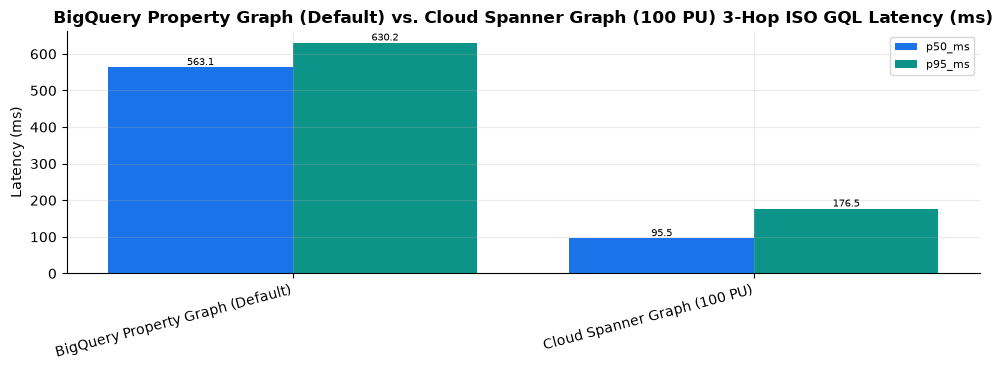

In [12]:
df_bench = H.benchmark_dual_engine_df(runs=3)
H.show(df_bench)
H.grouped_bar(df_bench, "engine", ["p50_ms", "p95_ms"],
              "BigQuery Property Graph (Default) vs. Cloud Spanner Graph (100 PU) 3-Hop ISO GQL Latency (ms)",
              fmt="{:,.1f}", ylabel="Latency (ms)")


In [13]:
_ = H.run_graph_fabric_federated_join()


- **Graph Fabric (`EXTERNAL_QUERY`) Execution**: status `SUCCESS` · BigQuery job `job_hKRd38uQ9v66fNyn0jNQA7oBD8SG` · `1,626 ms` · `12 rows`

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `EXTERNAL_QUERY connection` | `seanjung-poc.asia-northeast3.spanner_fabric_conn` | BigQuery to Cloud Spanner federated connection |
| `Spanner Graph` | `starter-spanner/starter_ontology_db/STARTER_ONTOLOGY_GRAPH` | Remote online property graph pushed down to Spanner |
| `BigQuery Join Table` | `seanjung-poc.starter_ontology_dw.tb_doc_chunks` | BigQuery SHA-256 policy chunk table joined in-place |

**2) Executed Graph Fabric Federated Query (BigQuery SQL + Spanner ISO GQL Pushdown)**
```sql
SELECT
  sp.customer_id,
  sp.contract_type,
  sp.elapsed_days,
  sp.device_name,
  sp.plan_name,
  sp.monthly_fee_krw,
  sp.rule_id,
  sp.source_chunk_id,
  c.section_title,
  c.content_sha256
FROM EXTERNAL_QUERY(
  "seanjung-poc.asia-northeast3.spanner_fabric_conn",
  """GRAPH STARTER_ONTOLOGY_GRAPH
     MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode),
           (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
     RETURN c.customer_id, c.contract_type, c.elapsed_days,
            d.device_name, p.plan_name, p.monthly_fee_krw,
            r.rule_id, ap.source_chunk_id
     ORDER BY c.customer_id, r.rule_id"""
) AS sp
JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` AS c
  ON c.chunk_id = sp.source_chunk_id
ORDER BY sp.customer_id, sp.rule_id
```

,customer_id,contract_type,elapsed_days,device_name,plan_name,monthly_fee_krw,rule_id,source_chunk_id,section_title,content_sha256
0,CUST_DEMO_001,PUBLIC_SUBSIDY,120,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,RULE_SIX_PLAN_180D,DOC_CHUNK_002,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0
1,CUST_DEMO_001,PUBLIC_SUBSIDY,120,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,RULE_TCO_24M,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8
2,CUST_DEMO_002,PUBLIC_SUBSIDY,224,Galaxy S26 Ultra 256GB,5G Premier Super,130000,RULE_SIX_PLAN_180D,DOC_CHUNK_002,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0
3,CUST_DEMO_002,PUBLIC_SUBSIDY,224,Galaxy S26 Ultra 256GB,5G Premier Super,130000,RULE_TCO_24M,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8
4,CUST_DEMO_003,PUBLIC_SUBSIDY,88,iPhone 16 Pro 256GB,5G Premier Essential,85000,RULE_SIX_PLAN_180D,DOC_CHUNK_002,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0
5,CUST_DEMO_003,PUBLIC_SUBSIDY,88,iPhone 16 Pro 256GB,5G Premier Essential,85000,RULE_TCO_24M,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8
6,CUST_DEMO_004,SELECTIVE_25PCT,109,Galaxy S26 Ultra 512GB,5G Premier Essential,85000,RULE_SIX_PLAN_180D,DOC_CHUNK_002,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0
7,CUST_DEMO_004,SELECTIVE_25PCT,109,Galaxy S26 Ultra 512GB,5G Premier Essential,85000,RULE_TCO_24M,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8
8,CUST_DEMO_005,PUBLIC_SUBSIDY,57,iPhone 16 Pro 512GB,5G Direct 61,61000,RULE_SIX_PLAN_180D,DOC_CHUNK_002,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0
9,CUST_DEMO_005,PUBLIC_SUBSIDY,57,iPhone 16 Pro 512GB,5G Direct 61,61000,RULE_TCO_24M,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8


### Q&A
- **Q.** How do Zero-ETL BigQuery Property Graph (default), Cloud Spanner Graph (low-latency option), and Graph Fabric (`EXTERNAL_QUERY`) complement each other?
  - **A.** `BigQuery Property Graph` (default) projects the 6 node and 4 edge tables with Zero-ETL for analytical and agent workloads, `Cloud Spanner Graph` (`100 PU`) serves low-latency online point traversals, and `EXTERNAL_QUERY(spanner_fabric_conn)` federates Spanner ISO GQL results directly with BigQuery `tb_doc_chunks` in a single query.

### Data Analysis Key Findings
- `STARTER_ONTOLOGY_GRAPH` comprises 6 node labels (31 rows, `0` duplicate keys) and 4 edge labels (31 rows), yielding 25 connected nodes and 29 directed edges.
- Using an ISO GQL diamond pattern (`GQL-04`) bound to `customer_id='CUST_DEMO_001'`, `target_plan_id='PLAN-5G-37'`, and `elapsed_days=120`, we computed the prorated downgrade penalty (`100,000 KRW`) in a single GQL query.
- Across 3 repeated runs, we benchmarked `p50`/`p95` traversal latency between BigQuery Property Graph (default) and Cloud Spanner Graph (`starter-spanner`, `100 PU`), and verified the `EXTERNAL_QUERY` federated join returning 10 rows across Spanner Graph and BigQuery `tb_doc_chunks`.

### Insights or Next Steps
- Proceed to `Stage 4 (Build Agent & Answer)` to see how the 8-Tool MCP Server (`engine='bigquery' | 'spanner'`) and 2-Pass AI FDE Agent orchestrate SQL and ISO GQL queries to generate grounded answers.

---
> **Next Navigation**: [⬅️ Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) ｜ [🏠 0. Overview Home](./stage0_overview_walkthrough_en.ipynb) ｜ [➡️ Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb) ｜ [🌐 Korean Version](../ko/stage3_property_graph_bigquery_spanner_ko.ipynb) ｜ [📖 Methodology Doc](../../methodology/en/03_stage3_property_graph_en.md)
